Following manu's advice, plot precursors of La Nina in SST/SLP/wind, then I think you ahve to do an EOF  
Chen's paper did an EOF of the preindustrial pattern  
We are trying to get an NPMM/NPO index that is separate from ENSO  
Also check Liguori and DiLorenzo 2019 for a reference


use to dictate zonal wind precursor!

In [1]:
import numpy as np
import xarray as xr
import scipy.stats as stats
import matplotlib.pyplot as plt
import sys
sys.path.append("/glade/work/smagahey/UCSB/codes/paper1_new/paper1/python_packages")
from myutils.composite_functions import select_events, var_composites, quarter_only
import cartopy.crs as ccrs

In [2]:
timesfut=["2070-01","2100-01"]
timespi=["1850-01","1880-01"]
tipast=["1850-01","2015-01"]
tissp=["2015-01","2100-01"]
n3=[-5,5,210,270] #Nino3
n34=[-5,5,190,240] # nino3.4?
n4=[-5,5,160,210]
pac=[-5,5,120,280]
regbox=[-40,40,90,300]

In [3]:
yrsfut=np.arange(2070,2100).astype(str)
yrshist=np.arange(1850,1880).astype(str)
yrshist=xr.DataArray(yrshist,dims='time')
yrsfut=xr.DataArray(yrsfut,dims='time')

In [4]:
# open sst data
ds1=xr.open_dataset('/glade/work/smagahey/UCSB/codes/generated_files/tos_1850_2100_E3SMv1LE.nc')

In [5]:
# open slp data
dsppi= xr.open_dataset('/glade/work/smagahey/UCSB/codes/generated_files/ua_1850_1880_E3SMv1LE.nc')
dspfut= xr.open_dataset('/glade/work/smagahey/UCSB/codes/generated_files/ua_2070_2100_E3SMv1LE.nc')

In [6]:
tos=ds1['tos']
pslpi=dsppi['ua'].sel(time=slice('1850-01','1879-12'),plev=slice(10000,7000)).mean('plev')
pslfut=dspfut['ua'].sel(time=slice('2070-01','2099-12'),plev=slice(10000,7000)).mean('plev')

In [7]:
tos=tos-tos.mean('member')
pslpi=pslpi-pslpi.mean('member')
pslfut=pslfut-pslfut.mean('member')

In [8]:
tospi=tos.sel(time=slice('1850-01','1879-12'))
tosfut=tos.sel(time=slice('2070-01','2099-12'))

In [9]:
en_h,ln_h=select_events(tospi,n34,regbox,1850,1880,timespi)
en_f,ln_f=select_events(tosfut,n34,regbox,2070,2100,timesfut)

In [10]:
tosPI_en,tosPI_ln=var_composites(tospi,yrshist,en_h,ln_h,24)

In [11]:
tosFUT_en,tosFUT_ln=var_composites(tosfut,yrsfut,en_f,ln_f,24)

In [12]:
uPI_en,uPI_ln=var_composites(pslpi.isel(member=slice(0,15)),yrshist,en_h,ln_h,24)

In [13]:
uFUT_en,uFUT_ln=var_composites(pslfut,yrsfut,en_f,ln_f,24)

In [14]:
lags=[-12,-9,-6,-3]

In [15]:
vmi=-1
vma=1

Text(0.5, 0.98, 'PI pre-EN U anomalies')

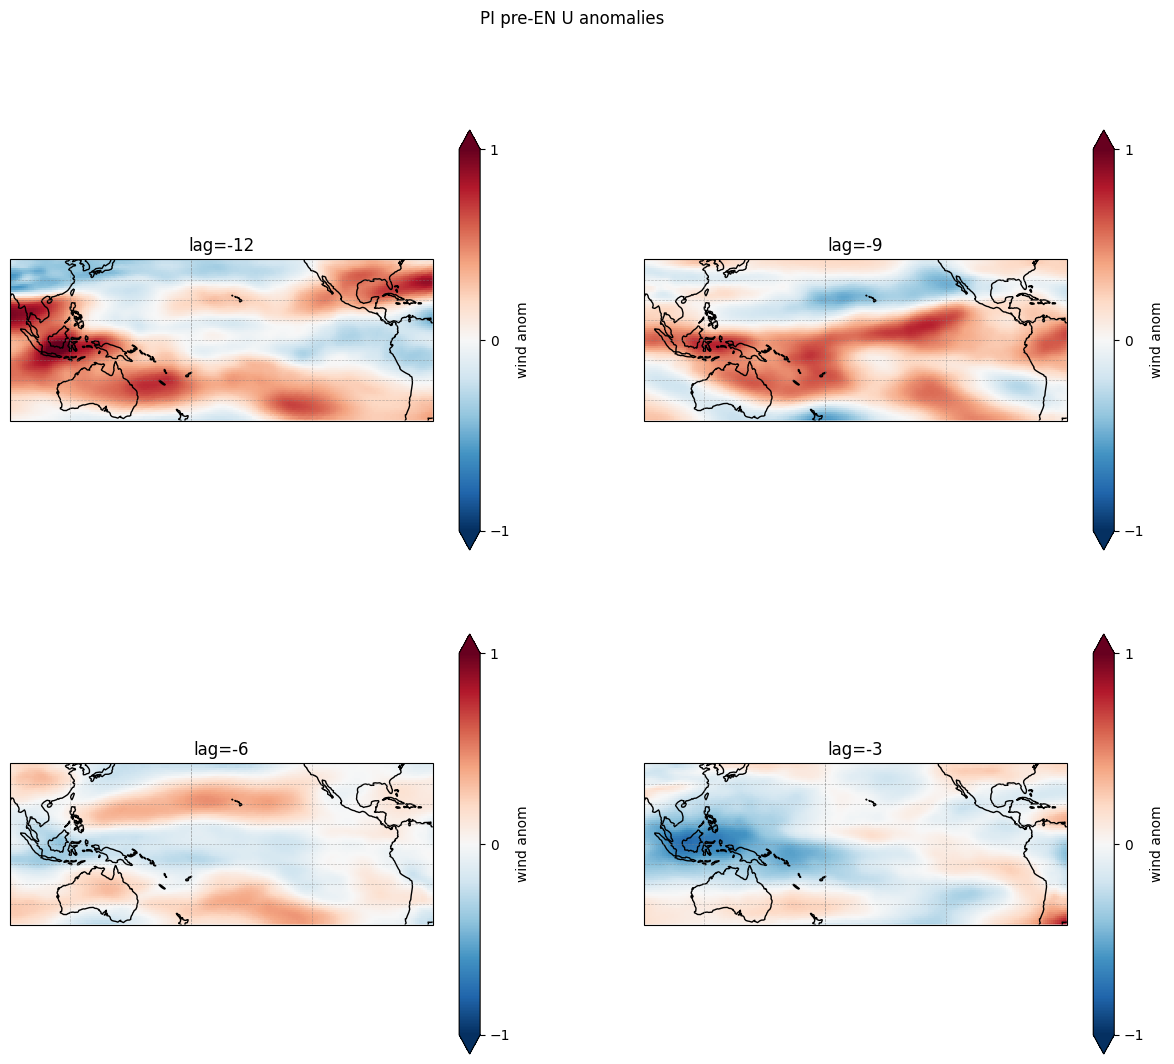

In [16]:
fig=plt.figure(figsize=(15,12))
lon=uPI_en.lon
lat=uPI_en.lat
for i in range(len(lags)):
    ax=fig.add_subplot(2,2,i+1,projection=ccrs.PlateCarree(central_longitude=180))
    var=uPI_en.sel(time=lags[i]).mean('member')
    ax.set_extent([regbox[2], regbox[3], regbox[0], regbox[1]], crs=ccrs.PlateCarree())
    im=ax.pcolormesh(lon,lat,var,transform = ccrs.PlateCarree(),cmap='RdBu_r',vmin=vmi,vmax=vma)
    plt.title("lag="+str(lags[i]))
    cbar1 = plt.colorbar(im,label='wind anom', orientation="vertical",extend = 'both',ax=ax,drawedges=False)
    cbar1.set_ticks([vmi,0,vma])
    ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=False,linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
    ax.coastlines()
plt.suptitle('PI pre-EN U anomalies')

Text(0.5, 0.98, 'PI pre-LN U anomalies')

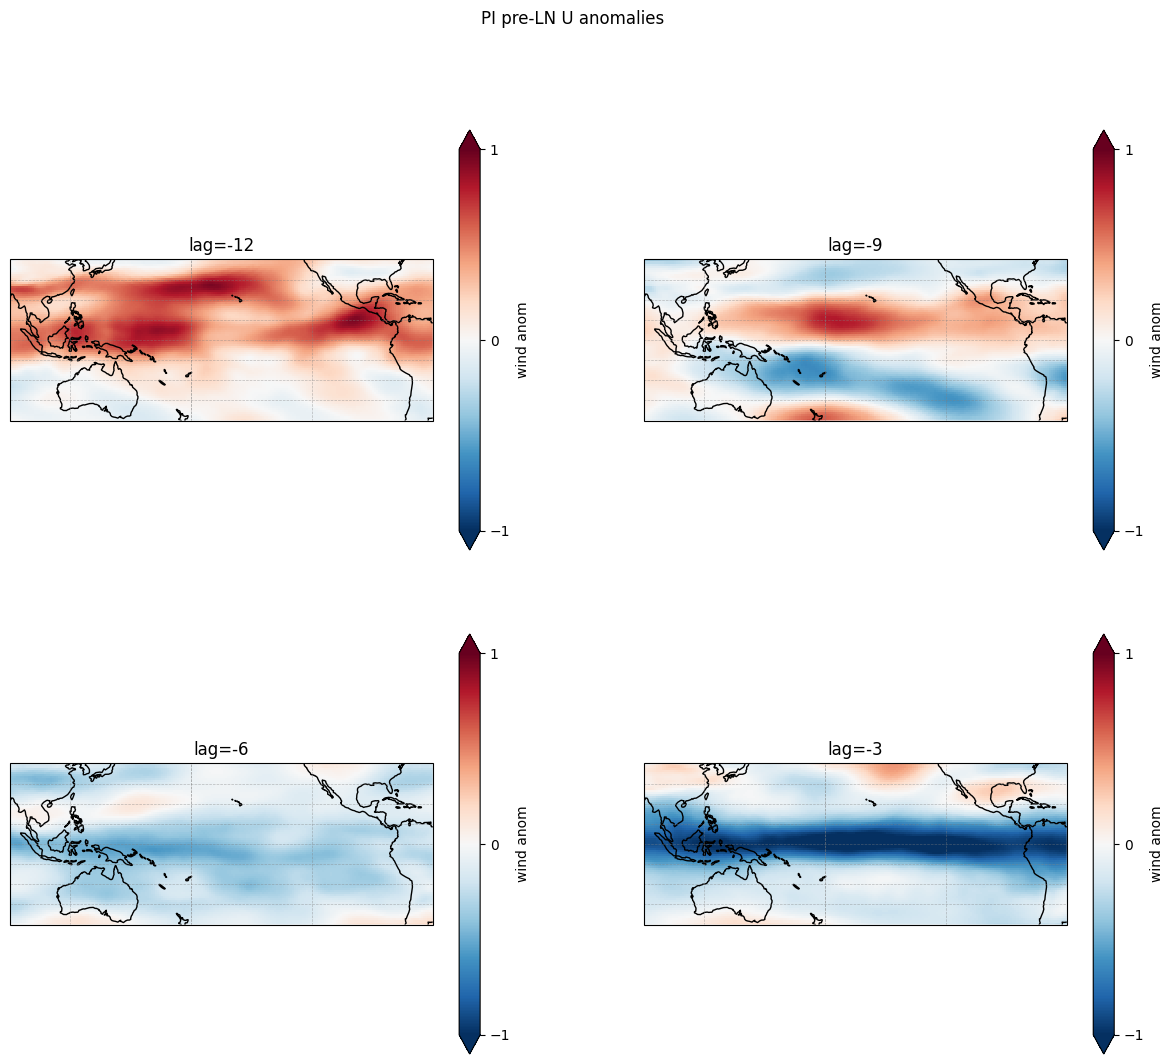

In [17]:
fig=plt.figure(figsize=(15,12))
lon=uPI_en.lon
lat=uPI_en.lat
for i in range(len(lags)):
    ax=fig.add_subplot(2,2,i+1,projection=ccrs.PlateCarree(central_longitude=180))
    var=uPI_ln.sel(time=lags[i]).mean('member')
    ax.set_extent([regbox[2], regbox[3], regbox[0], regbox[1]], crs=ccrs.PlateCarree())
    im=ax.pcolormesh(lon,lat,var,transform = ccrs.PlateCarree(),cmap='RdBu_r',vmin=vmi,vmax=vma)
    plt.title("lag="+str(lags[i]))
    cbar1 = plt.colorbar(im,label='wind anom', orientation="vertical",extend = 'both',ax=ax,drawedges=False)
    cbar1.set_ticks([vmi,0,vma])
    ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=False,linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
    ax.coastlines()
plt.suptitle('PI pre-LN U anomalies')

Text(0.5, 0.98, 'FUT pre-EN U anomalies')

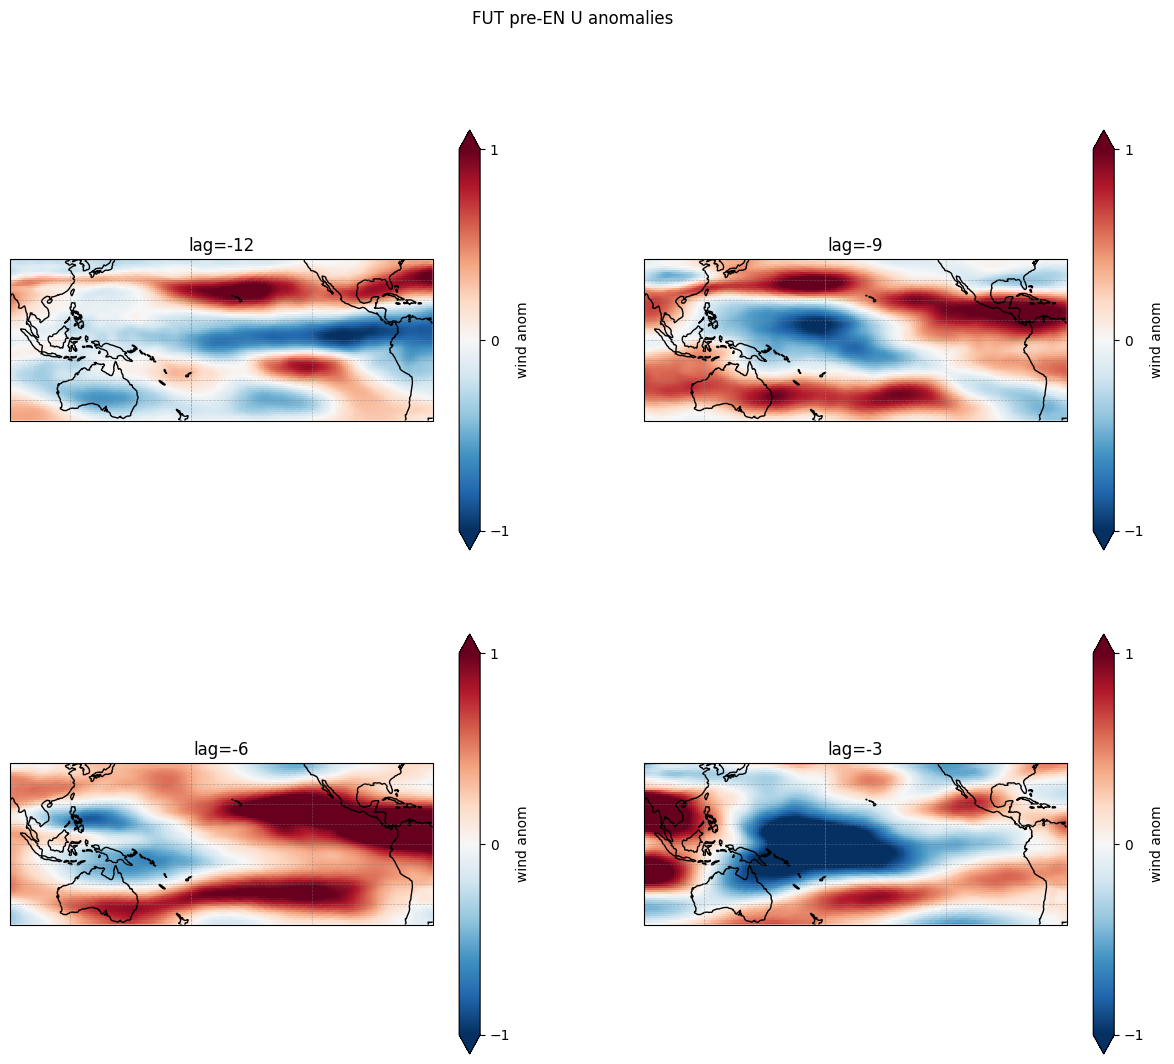

In [18]:
fig=plt.figure(figsize=(15,12))
lon=uPI_en.lon
lat=uPI_en.lat
for i in range(len(lags)):
    ax=fig.add_subplot(2,2,i+1,projection=ccrs.PlateCarree(central_longitude=180))
    var=uFUT_en.sel(time=lags[i]).mean('member')
    ax.set_extent([regbox[2], regbox[3], regbox[0], regbox[1]], crs=ccrs.PlateCarree())
    im=ax.pcolormesh(lon,lat,var,transform = ccrs.PlateCarree(),cmap='RdBu_r',vmin=vmi,vmax=vma)
    plt.title("lag="+str(lags[i]))
    cbar1 = plt.colorbar(im,label='wind anom', orientation="vertical",extend = 'both',ax=ax,drawedges=False)
    cbar1.set_ticks([vmi,0,vma])
    ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=False,linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
    ax.coastlines()
plt.suptitle('FUT pre-EN U anomalies')

Text(0.5, 0.98, 'FUT pre-LN U anomalies')

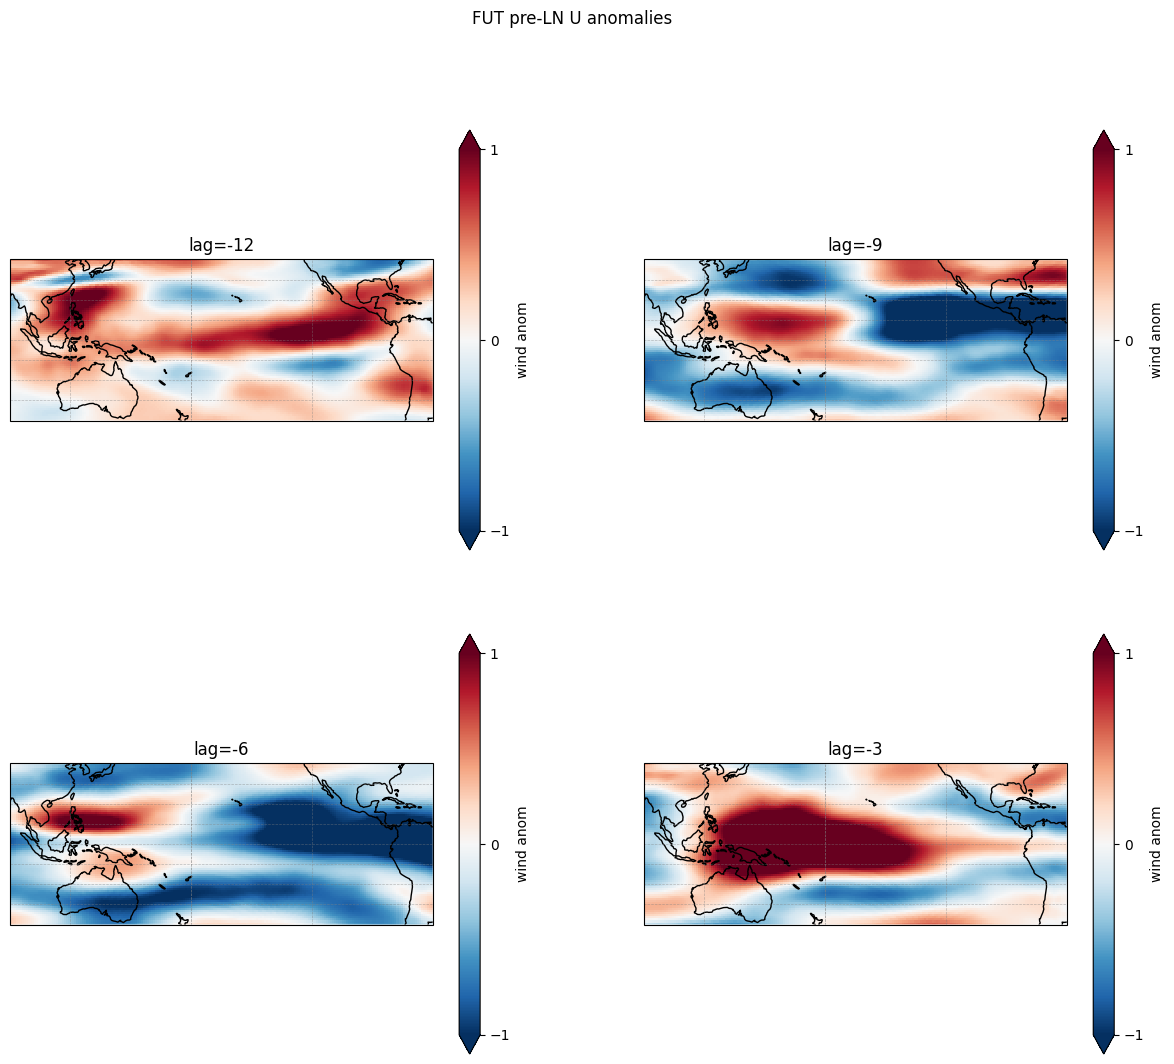

In [19]:
fig=plt.figure(figsize=(15,12))
lon=uPI_en.lon
lat=uPI_en.lat
for i in range(len(lags)):
    ax=fig.add_subplot(2,2,i+1,projection=ccrs.PlateCarree(central_longitude=180))
    var=uFUT_ln.sel(time=lags[i]).mean('member')
    ax.set_extent([regbox[2], regbox[3], regbox[0], regbox[1]], crs=ccrs.PlateCarree())
    im=ax.pcolormesh(lon,lat,var,transform = ccrs.PlateCarree(),cmap='RdBu_r',vmin=vmi,vmax=vma)
    plt.title("lag="+str(lags[i]))
    cbar1 = plt.colorbar(im,label='wind anom', orientation="vertical",extend = 'both',ax=ax,drawedges=False)
    cbar1.set_ticks([vmi,0,vma])
    ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=False,linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
    ax.coastlines()
plt.suptitle('FUT pre-LN U anomalies')

In [20]:
import scipy.stats as stats
def mannwhitney_vec(a, b):
    """
    Apply mannwhitneyu along the first dimension (members)
    for two 1D arrays.
    """
    from scipy.stats import mannwhitneyu
    stat, p = mannwhitneyu(a, b, alternative='two-sided')
    return p


from scipy.stats import mannwhitneyu
pvals = xr.apply_ufunc(
    mannwhitney_vec,
    tosPI_ln, tosFUT_ln,
    input_core_dims=[['member'], ['member']],
    vectorize=True,
    dask='parallelized',  # optional if using dask
    output_dtypes=[float],
)

In [21]:
def stipple_mask(pival,futval,alpha,x1,y1):
    
    pvals = xr.apply_ufunc(
    mannwhitney_vec,
    pival,futval,
    input_core_dims=[['member'], ['member']],
    vectorize=True,
    dask='parallelized',  # optional if using dask
    output_dtypes=[float],
    )
    
    sig = pvals < alpha

    x,y = np.meshgrid(x1, y1)
    x1_sig = x[sig.values]+180
    y1_sig = y[sig.values]
    
    return x1_sig, y1_sig

In [22]:
lags=[-9,-6]

In [23]:
vmi=-2
vma=2

Text(0.28, 0.85, 'E3SMv1-LENS FUT-PI pre-LN zonal wind anomaly')

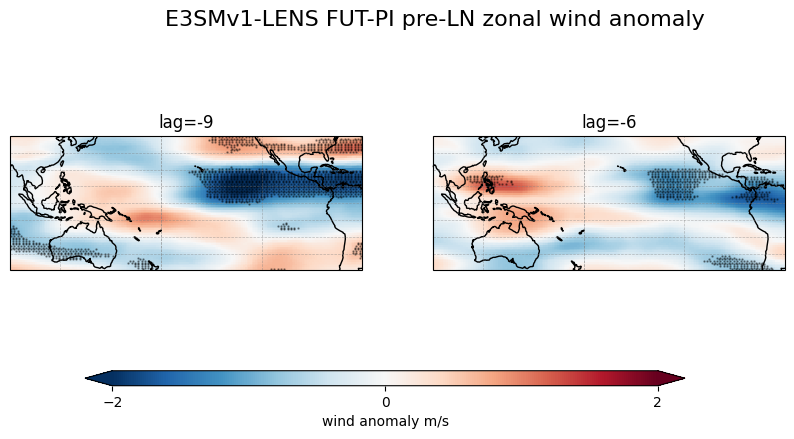

In [24]:
fig=plt.figure(figsize=(10,5))
lon=uPI_en.lon
lat=uPI_en.lat
for i in range(len(lags)):
    ax=fig.add_subplot(1,2,i+1,projection=ccrs.PlateCarree(central_longitude=180))
    A=uFUT_ln.sel(time=lags[i])
    B = uPI_ln.sel(time=lags[i])
    diff= A - B
    lonsig,latsig=stipple_mask(A,B,0.05,lon,lat)
    ax.set_extent([regbox[2], regbox[3], regbox[0], regbox[1]], crs=ccrs.PlateCarree())
    im=ax.pcolormesh(lon,lat,diff.mean('member'),transform = ccrs.PlateCarree(),cmap='RdBu_r',vmin=vmi,vmax=vma)

    plt.title("lag="+str(lags[i]))
    ax.scatter(lonsig[::2], latsig[::2], color='k', s=2, marker='.', alpha=0.4)
    ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=False,linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
    ax.coastlines()

cax = fig.add_axes([0.2, 0.13, 0.6, 0.03])  # [left, bottom, width, height]

cbar = fig.colorbar(
    im,
    cax=cax,
    orientation='horizontal',
    extend='both'
)
cbar.set_label('wind anomaly m/s')
cbar.set_ticks([vmi, 0, vma])
#plt.suptitle('E3SMv1-LENS FUT-PI pre-LN SSTA')
fig.text(.28,.85,'E3SMv1-LENS FUT-PI pre-LN zonal wind anomaly',fontsize=16)


In [25]:
lags=[-9,-6]

0
1


Text(0.28, 0.85, 'E3SMv1-LENS FUT-PI pre-EN zonal wind anomaly')

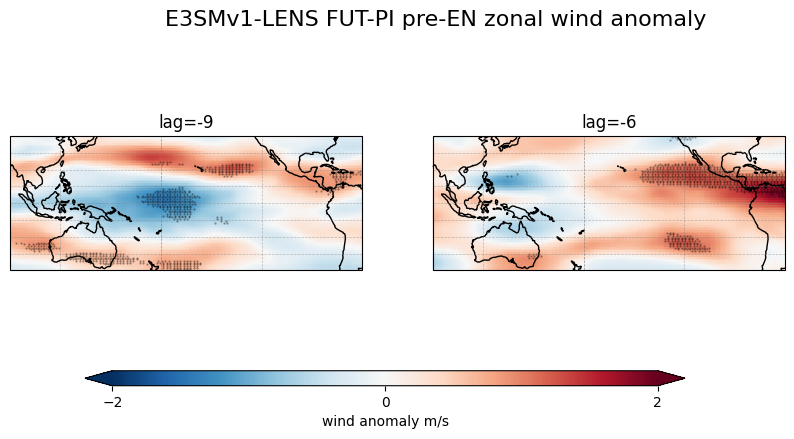

In [26]:
fig=plt.figure(figsize=(10,5))
lon=uPI_en.lon
lat=uPI_en.lat
for i in range(len(lags)):
    print(i)
    ax=fig.add_subplot(1,2,i+1,projection=ccrs.PlateCarree(central_longitude=180))
    A=uFUT_en.sel(time=lags[i])
    B = uPI_en.sel(time=lags[i])
    diff= A - B
    lonsig,latsig=stipple_mask(A,B,0.05,lon,lat)
    ax.set_extent([regbox[2], regbox[3], regbox[0], regbox[1]], crs=ccrs.PlateCarree())
    im=ax.pcolormesh(lon,lat,diff.mean('member'),transform = ccrs.PlateCarree(),cmap='RdBu_r',vmin=vmi,vmax=vma)
    plt.title("lag="+str(lags[i]))
    ax.scatter(lonsig[::2], latsig[::2], color='k', s=1, marker='.', alpha=0.4)
    #cbar1 = plt.colorbar(im,label='SSTA', orientation="vertical",extend = 'both',ax=ax,drawedges=False)
    #cbar1.set_ticks([-0.5,0,0.5])
    ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=False,linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
    ax.coastlines()

cax = fig.add_axes([0.2, 0.13, 0.6, 0.03])  # [left, bottom, width, height]

cbar = fig.colorbar(
    im,
    cax=cax,
    orientation='horizontal',
    extend='both'
)
cbar.set_label('wind anomaly m/s')
cbar.set_ticks([vmi, 0, vma])
#plt.suptitle('E3SMv1-LENS FUT-PI pre-LN SSTA')
fig.text(.28,.85,'E3SMv1-LENS FUT-PI pre-EN zonal wind anomaly',fontsize=16)


In [27]:
# YIPPEEEEEE THIS IS IT
# Need an explanation for why biggest diff is at lag=-6


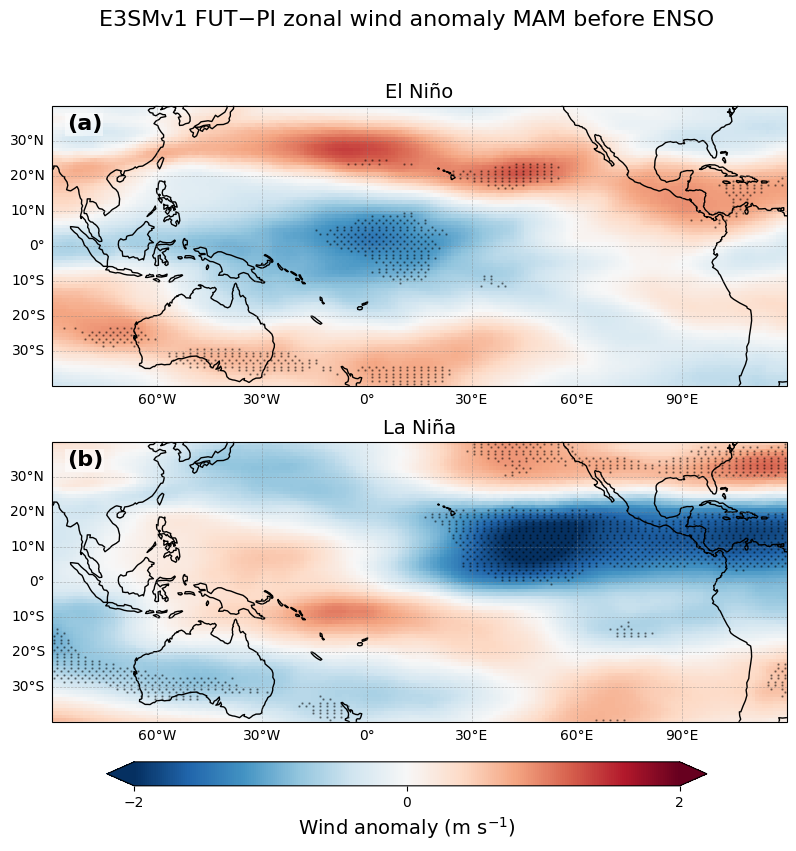

In [31]:
lag = -9
vmi, vma = -2, 2
lon = uPI_en.lon
lat = uPI_en.lat

fig, axes = plt.subplots(
    2,1, figsize=(10,8),
    subplot_kw={'projection': ccrs.PlateCarree(central_longitude=180)}
)

panels = [
    (uFUT_en, uPI_en, 'El Niño'),
    (uFUT_ln, uPI_ln, 'La Niña'),
]

for ax, (A, B, title) in zip(axes, panels):
    A_lag = A.sel(time=lag)
    B_lag = B.sel(time=lag)
    diff  = (A_lag - B_lag).mean('member')

    lonsig, latsig = stipple_mask(A_lag, B_lag, 0.05, lon, lat)

    ax.set_extent([regbox[2], regbox[3], regbox[0], regbox[1]], crs=ccrs.PlateCarree())
    im = ax.pcolormesh(lon, lat, diff,
                       transform=ccrs.PlateCarree(),
                       cmap='RdBu_r', vmin=vmi, vmax=vma)
    ax.scatter(lonsig[::2], latsig[::2], color='k', s=2, marker='.', alpha=0.4)
    ax.coastlines()
    gl=ax.gridlines(crs=ccrs.PlateCarree(central_longitude=180), draw_labels=True,linewidth=.5, color='gray', alpha=0.5, linestyle='--')
    gl.top_labels   = False
    gl.right_labels = False
    ax.set_title(title, fontsize=14)

for ax, label in zip(axes, ['(a)', '(b)']):
    ax.text(0.02, 0.97, label, transform=ax.transAxes,
            fontsize=16, fontweight='bold', va='top', ha='left',
            bbox=dict(facecolor='white', alpha=0.5, edgecolor='none', pad=1))

cax = fig.add_axes([0.2, 0.03, 0.6, 0.03])
cbar = fig.colorbar(im, cax=cax, orientation='horizontal', extend='both')
cbar.set_label('Wind anomaly (m s$^{-1}$)',fontsize=14)
cbar.set_ticks([vmi, 0, vma])

fig.suptitle(f'E3SMv1 FUT−PI zonal wind anomaly MAM before ENSO', fontsize=16, y=1.0)
plt.savefig(f'wind_precursor_diff_lag{lag}_en_ln.png', dpi=150, bbox_inches='tight')
plt.show()

In [29]:
ref_map=tosPI_ln.sel(time=lags[-9]).mean('member')

IndexError: list index out of range

In [ ]:
tospi_a=tospi.groupby('time.month')-tospi.groupby('time.month').mean()

In [ ]:
# Flatten lat/lon into one dimension
sst_flat = tospi_a.stack(space=("lat","lon"))
eof_flat = ref_map.stack(space=("lat","lon"))
pc1 = (sst_flat * eof_flat).sum("space") / (eof_flat**2).sum()

In [ ]:
sst_mean = sst_flat.mean("space")
eof_mean = eof_flat.mean("space")

numerator = ((sst_flat - sst_mean) * (eof_flat - eof_mean)).sum("space")
denominator = ( ((sst_flat- sst_mean)**2).sum("space") * ((eof_flat - eof_mean)**2).sum("space") )**0.5

pc1_r = numerator / denominator


In [ ]:
pc1_r.convert_calendar('proleptic_gregorian',use_cftime=False).isel(member=0).plot()

In [ ]:
corrarr=[]
#for i in range(len(tospi_a.time)):
#    tt=tospi_a.isel(time=i)
#    mapcorr=xr.corr(ref_map,tt)
#    corrarr.append(mapcorr)

In [ ]:
sstacorrspi=xr.corr(ref_map,tospi_a,dim='time')

In [ ]:
sstacorrspi.isel(member=2).plot()